16-11-2026

Vandaag gedaan: We hebben een dataset gevonden: https://causeweb.org/tshs/tumor-growth/ Deze dataset metingen van de tumorgroei van een paar muizen voor een experiment. Er zijn 4 groepen, maar ik denk dat we voor deze casus alleen maar de controlegroep gaan gebruiken. Een paar dagen zijn niet gemeten, maar er zijn genoeg metingen dat ik denk dat we er niet erg veel last van zullen hebben of dat het daardoor onbruikbaar is geworden. Verder is mijn laptop leeg en doet git op linux heel erg moeilijk, dus ik laat het hierbij voor vandaag.

Voor morgen: Eerst de data analyseren door middel van een plotje, kijken hoe de groei eruit ziet. Daarna kijken of de code voor al die modellen toegepast kan worden op de data. Het solven kan wel voor later, want daar snap ik niet echt al te veel van.


______________________

18-11-2026

Vandaag gedaan: eerst een korte analyse op de data:


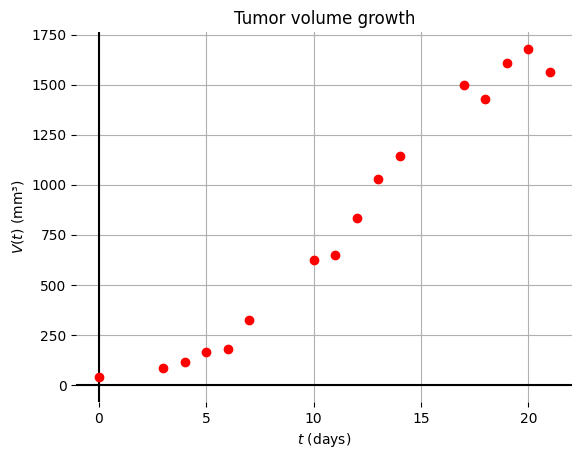

In [1]:
import pandas as pd
from matplotlib import pyplot as plt

ts = [0, 3, 4, 5, 6, 7, 10, 11, 12, 13, 14, 17, 18, 19, 20, 21]
Vs = [41.8, 85, 114, 162.3, 178.3, 325, 623.7, 648.4, 835.9, 1030.4, 1141.8, 1499.9, 1429.3, 1609.3, 1678.3, 1564]

pd.DataFrame({'$t$': ts, '$V$': Vs}).T

plt.axhline(0.0, color='k'); plt.axvline(0.0, color='k')
plt.plot(ts, Vs, 'or')
plt.title('Tumor volume growth'); plt.xlabel('$t$ (days)'); plt.ylabel('$V(t)$ (mm³)')
plt.grid(True); plt.box(False)
plt.show()

Je ziet dat op dag 3 de groei van de tumor aan het begin best sloom verloopt, en dat pas op dag 7 er echt dikke stijging in komt. Op dag 18 krimpt de tumor voor een dag, voordat het weer groeit op dag 19 en z'n hoogst gemeten punt bereikt op dag 20. Op de laatste dag, dag 21, krimt het echter weer.

In [5]:
def exponential(V, c):
    return c * V

def linear(c):
    return c

def mendelsohn(c, V, d):
    return c * V**d

def exponential_smooth(c, V, Vmax):
    return c * (Vmax - V)

def logistic(c, V, Vmax):
    return c * V * (Vmax - V)

def montroll(c, V, d, Vmax):
    return c * V * (Vmax**d - V**d)

def allee_effect(c, V, Vmin, Vmax):
    return c * (V - Vmin) * (Vmax - V)

Methodes ofzo

In [11]:
def exponential_solution(t, V0, c):
    return V0 + exponential(c) * t

19-11-2026

Vandaag gedaan:

In [6]:
def dingetje(V, c, delta_t):
    change = exponential(V, c) * delta_t
    return V + change

45.98
50.577999999999996
55.635799999999996
61.19938
67.319318
74.0512498
81.45637477999999
89.60201225799999
98.56221348379998
108.41843483217998
